In [365]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt

In [366]:
img = cv.imread('lab5/periodic_noise.jpg', cv.IMREAD_GRAYSCALE)

In [367]:
# 1

In [368]:
dft = cv.dft(np.float32(img),flags = cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

In [369]:
rows, cols = img.shape
center_x, center_y = rows // 2, cols // 2

In [370]:
x = np.arange(rows)
y = np.arange(cols)
X, Y = np.meshgrid(x, y, indexing='ij')

In [371]:
D = np.sqrt((X - center_x)**2 + (Y - center_y)**2)

In [372]:
D0 = 50
lowpass = np.exp(-(D**2) / (2 * (D0**2)))
gaussian_highpass = 1.0 - lowpass

In [373]:
mask = np.repeat(gaussian_highpass[:, :, np.newaxis], 2, axis=2)

In [374]:
dft_shift_filtered = dft_shift * mask

In [375]:
f_ishift = np.fft.ifftshift(dft_shift_filtered)
img_back = cv.idft(f_ishift)
img_back = cv.magnitude(img_back[:,:,0], img_back[:,:,1])
img_back = cv.normalize(img_back, None, 0, 255, cv.NORM_MINMAX).astype(np.uint8)

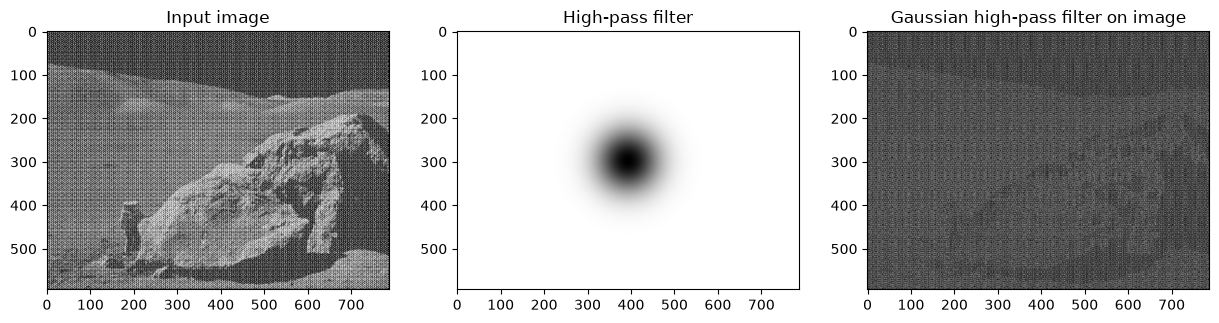

In [376]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1);
plt.title('Input image')
plt.imshow(img, cmap='gray')

plt.subplot(1, 3, 2);
plt.title('High-pass filter')
plt.imshow(gaussian_highpass, cmap='gray')

plt.subplot(1, 3, 3);
plt.title('Gaussian high-pass filter on image')
plt.imshow(img_back, cmap='gray')

plt.show()

In [377]:
# 2

In [378]:
ksize = 9
sigma = 5.0

In [379]:
g_1d = cv.getGaussianKernel(ksize, sigma, cv.CV_32F)
kernel = np.outer(g_1d, g_1d)

In [380]:
kernel_padded = np.zeros((rows, cols), dtype=np.float32)
kernel_padded[:ksize, :ksize] = kernel

In [381]:
kernel_padded = np.roll(kernel_padded, -ksize // 2, axis=0)
kernel_padded = np.roll(kernel_padded, -ksize // 2, axis=1)

In [382]:
dft_img = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_kernel = cv.dft(kernel_padded, flags=cv.DFT_COMPLEX_OUTPUT)

In [383]:
dft_conv = cv.mulSpectrums(dft_img, dft_kernel, flags=0)

In [384]:
img_back = cv.idft(dft_conv)
img_back = cv.magnitude(img_back[:, :, 0], img_back[:, :, 1])

In [385]:
result_conv = cv.normalize(img_back, None, 0, 255, cv.NORM_MINMAX).astype(np.uint8)

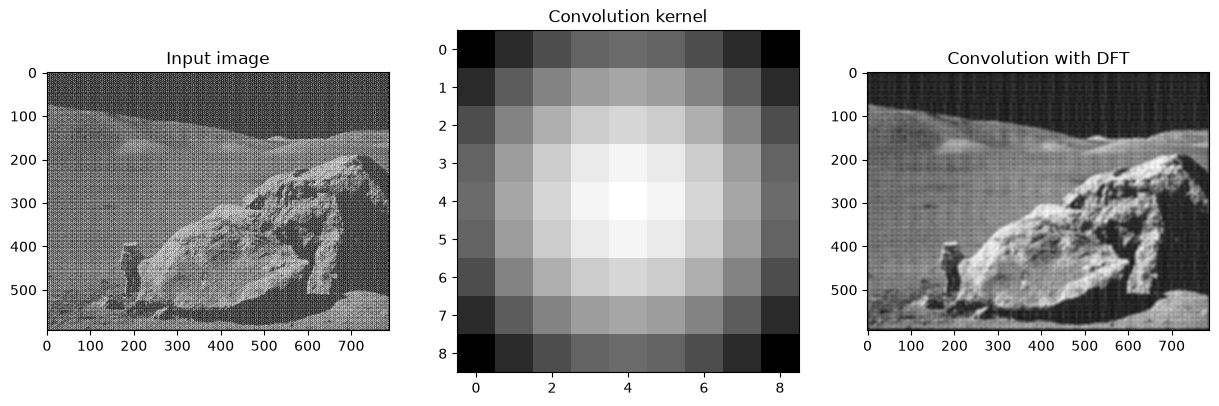

In [386]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.title('Input image')
plt.imshow(img, cmap='gray')

plt.subplot(1, 3, 2)
plt.title('Convolution kernel')
plt.imshow(kernel, cmap='gray')

plt.subplot(1, 3, 3)
plt.title('Convolution with DFT')
plt.imshow(result_conv, cmap='gray')

plt.show()

In [387]:
# 3

In [388]:
mag = 20 * np.log(cv.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1]) + 1e-5)

In [389]:
u = np.arange(rows)
v = np.arange(cols)
U, V = np.meshgrid(u, v, indexing='ij')

In [390]:
center_dist = np.sqrt((U - center_x)**2 + (V - center_y)**2)

In [391]:
mag_periphery = mag.copy()
mag_periphery[center_dist < 50] = 0

In [392]:
magnitude_norm = cv.normalize(mag_periphery, None, 0, 255, cv.NORM_MINMAX).astype(np.uint8)

In [393]:
_, thresh = cv.threshold(magnitude_norm, np.percentile(magnitude_norm, 99.9), 255, cv.THRESH_BINARY)

In [394]:
noise_peaks = cv.findNonZero(thresh)

In [395]:
notch_mask = np.ones((rows, cols), dtype=np.float32)
r = 3

In [396]:
if noise_peaks is not None:
    for pt in noise_peaks:
        px, py = pt.ravel()
    
        dist_from_peak = np.sqrt((U - py)**2 + (V - px)**2)
        notch_mask[dist_from_peak <= r] = 0.0

In [397]:
mask = np.repeat(notch_mask[:, :, np.newaxis], 2, axis=2)

In [398]:
dft_shift_filtered = dft_shift * mask

In [399]:
f_ishift = np.fft.ifftshift(dft_shift_filtered)
img_back = cv.idft(f_ishift)
img_back = cv.magnitude(img_back[:, :, 0], img_back[:, :, 1])

In [400]:
denoised_result = cv.normalize(img_back, None, 0, 255, cv.NORM_MINMAX).astype(np.uint8)

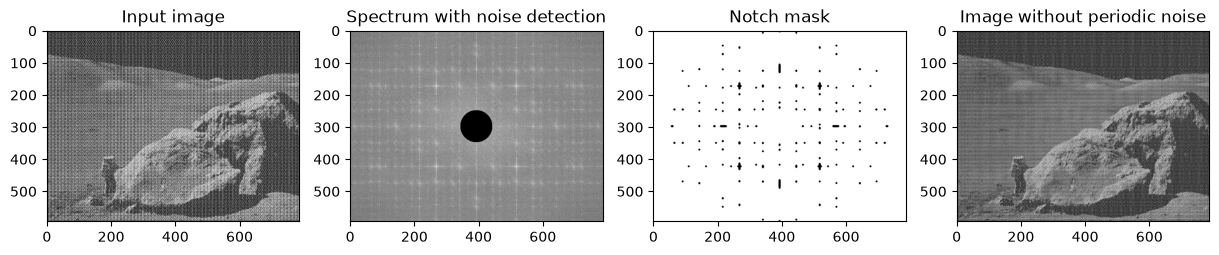

In [401]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 4, 1)
plt.title('Input image')
plt.imshow(img, cmap='gray')

plt.subplot(1, 4, 2)
plt.title('Spectrum with noise detection')
plt.imshow(mag_periphery, cmap='gray')

plt.subplot(1, 4, 3)
plt.title('Notch mask')
plt.imshow(notch_mask, cmap='gray')

plt.subplot(1, 4, 4)
plt.title('Image without periodic noise')
plt.imshow(denoised_result, cmap='gray')

plt.show()